In [1]:
# Setup and database connection
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Connect to the full HW4 database
db_path = '../../../Lectures/modeling/data/equities_top2000.duckdb'
con = duckdb.connect(db_path)

In [3]:
# Extract all valid prices (including non-members for marking/exiting open positions)
# Join universe_membership on next_date (entry session t+1) to prevent look-ahead bias
query = """
WITH clean_prices AS (
    SELECT 
        date,
        symbol AS ticker,
        adj_close AS close,
        LEAD(date) OVER (PARTITION BY symbol ORDER BY date) AS next_date,
        LEAD(adj_close) OVER (PARTITION BY symbol ORDER BY date) AS entry_price,
        LEAD(date, 64) OVER (PARTITION BY symbol ORDER BY date) AS exit_date,
        LEAD(adj_close, 64) OVER (PARTITION BY symbol ORDER BY date) AS exit_price
    FROM prices
    WHERE date >= '2009-09-01'
      AND adj_close > 0
      AND isfinite(adj_close)
)
SELECT 
    p.date,
    p.ticker,
    p.close,
    p.next_date,
    p.entry_price,
    p.exit_date,
    p.exit_price,
    CASE WHEN m.symbol IS NOT NULL THEN 1 ELSE 0 END AS is_eligible
FROM clean_prices p
LEFT JOIN universe_membership m
    ON p.ticker = m.symbol
    AND p.next_date >= m.quarter_start
    AND p.next_date < m.quarter_start + INTERVAL '3 months'
ORDER BY p.ticker, p.date
"""
df = con.execute(query).df()
df['date'] = pd.to_datetime(df['date'])
df['next_date'] = pd.to_datetime(df['next_date'])
df['exit_date'] = pd.to_datetime(df['exit_date'])

# Compute trailing features at close t
ret_1d = df.groupby('ticker')['close'].pct_change()
df['mom_20d'] = df['close'] / df.groupby('ticker')['close'].shift(20) - 1
df['mom_60d'] = df['close'] / df.groupby('ticker')['close'].shift(60) - 1
df['vol_20d'] = ret_1d.groupby(df['ticker']).rolling(20).std().reset_index(level=0, drop=True)

# Target: 90-day forward return starting at t+1 entry close
df['target_90d'] = df['exit_price'] / df['entry_price'] - 1

In [4]:
# Strict chronological split: training targets must finish by 2015-12-31 (before 2016 Q1 buffer)
features = ['mom_20d', 'mom_60d', 'vol_20d']

train_mask = (
    (df['is_eligible'] == 1) &
    (df['next_date'] >= '2010-01-01') &
    (df['exit_date'] <= '2015-12-31')
)
train_df = df[train_mask].dropna(subset=features + ['target_90d']).copy()

# Test set: eligible candidates entering from 2016-04-01 through 2026-09-30
test_mask = (
    (df['is_eligible'] == 1) &
    (df['next_date'] >= '2016-04-01') &
    (df['next_date'] <= '2026-09-30')
)
test_df = df[test_mask].dropna(subset=features + ['entry_price']).copy()

# Fit preprocessing and Ridge regression strictly on development data
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[features])
y_train = train_df['target_90d'].clip(-1.0, 5.0)  # Cap extreme split-artifact outliers in train only

model = Ridge(alpha=10.0)
model.fit(X_train, y_train)

# Predict expected returns for test candidates
test_df['predicted_return'] = model.predict(scaler.transform(test_df[features]))

In [5]:
# Backtester parameters and assumptions:
# - Initial cash: $1,000,000, long-only, 0% cash interest, 10 bps transaction cost per trade
# - Signal at close t -> execute at close t+1 -> hold for 90 calendar days
INITIAL_CASH = 1_000_000.0
HOLDING_DAYS = 90
TOP_N = 20
COST_BPS = 0.001

# Full price lookup across all tickers (handles stocks exiting the universe while held)
price_df = df[df['date'] >= '2016-03-15'][['date', 'ticker', 'close']]
price_lookup = dict(zip(zip(price_df['date'], price_df['ticker']), price_df['close']))

# Trading calendar for the final test period
cal_dates = con.execute(
    "SELECT date FROM calendar WHERE date >= '2016-04-01' AND date <= '2026-09-30' ORDER BY date"
).df()['date']
cal_dates = list(pd.to_datetime(cal_dates))

# Group eligible signals by signal date t
signals_by_date = {d: grp for d, grp in test_df.groupby('date')}

cash = INITIAL_CASH
open_positions = []
closed_trades = []
daily_history = []

for i, current_date in enumerate(cal_dates):
    # 1. Update open positions and process 90-calendar-day maturity exits at current_date close
    surviving_positions = []
    positions_value = 0.0

    for pos in open_positions:
        quote = price_lookup.get((current_date, pos['ticker']))
        if quote is not None:
            pos['last_price'] = quote
            pos['stale_days'] = 0
        else:
            pos['stale_days'] += 1

        is_mature = current_date >= pos['maturity_date']
        is_delisted = pos['stale_days'] > 5  # Liquidate at last mark if halted/delisted > 5 sessions

        if (is_mature and quote is not None) or is_delisted:
            sell_price = pos['last_price']
            proceeds = pos['shares'] * sell_price * (1.0 - COST_BPS)
            cash += proceeds
            closed_trades.append({
                'ticker': pos['ticker'],
                'signal_date': pos['signal_date'],
                'entry_date': pos['entry_date'],
                'exit_date': current_date,
                'cal_days_held': (current_date - pos['entry_date']).days,
                'delisted_exit': is_delisted
            })
        else:
            positions_value += pos['shares'] * pos['last_price']
            surviving_positions.append(pos)

    open_positions = surviving_positions
    total_value = cash + positions_value

    daily_history.append({
        'date': current_date,
        'cash': cash,
        'positions_value': positions_value,
        'total_value': total_value,
        'open_lots': len(open_positions)
    })

    # 2. Plan orders at close t for execution at next session's close (t+1)
    if i + 1 < len(cal_dates) and cash > 10_000.0:
        next_session = cal_dates[i + 1]
        day_signals = signals_by_date.get(current_date)

        if day_signals is not None:
            held_tickers = {p['ticker'] for p in open_positions}
            candidates = day_signals[
                (day_signals['next_date'] == next_session) &
                (~day_signals['ticker'].isin(held_tickers)) &
                (day_signals['predicted_return'] > 0)
            ]

            if not candidates.empty:
                picks = candidates.nlargest(TOP_N, 'predicted_return')
                alloc_per_stock = cash / len(picks)

                for _, row in picks.iterrows():
                    fill_price = row['entry_price']
                    shares = (alloc_per_stock * (1.0 - COST_BPS)) / fill_price
                    cash -= alloc_per_stock
                    open_positions.append({
                        'ticker': row['ticker'],
                        'shares': shares,
                        'signal_date': current_date,
                        'entry_date': next_session,
                        'maturity_date': next_session + pd.Timedelta(days=HOLDING_DAYS),
                        'last_price': fill_price,
                        'stale_days': 0
                    })

portfolio_df = pd.DataFrame(daily_history).set_index('date')
trades_df = pd.DataFrame(closed_trades)

# Accounting & timing verification checks
max_acct_err = (portfolio_df['total_value'] - (portfolio_df['cash'] + portfolio_df['positions_value'])).abs().max()
normal_trades = trades_df[~trades_df['delisted_exit']]

print("=== Accounting & Timing Verification ===")
print(f"Minimum cash balance:         ${portfolio_df['cash'].min():,.2f} (must be >= 0)")
print(f"Max daily accounting error:   ${max_acct_err:.2e}")
print(f"All entries strictly > t:     {(trades_df['entry_date'] > trades_df['signal_date']).all()}")
print(f"Min holding days (non-halt):  {normal_trades['cal_days_held'].min()} days (must be >= 90)")
print(f"Total closed trades:          {len(trades_df)} (delisted/stale exits: {trades_df['delisted_exit'].sum()})")

=== Accounting & Timing Verification ===
Minimum cash balance:         $-0.00 (must be >= 0)
Max daily accounting error:   $0.00e+00
All entries strictly > t:     True
Min holding days (non-halt):  90 days (must be >= 90)
Total closed trades:          1342 (delisted/stale exits: 11)


Metric               | Strategy        | S&P 500 (^SP500TR)
----------------------------------------------------------
Final Value          | $1,398,796.35 | $4,402,746.78
CAGR                 | 3.25%         | 15.17%
Sharpe Ratio         | 0.20            | 0.77
Max Drawdown         | -58.70%         | -33.79%

Outperformance vs Benchmark: $-3,003,950.43 (-11.92% CAGR)


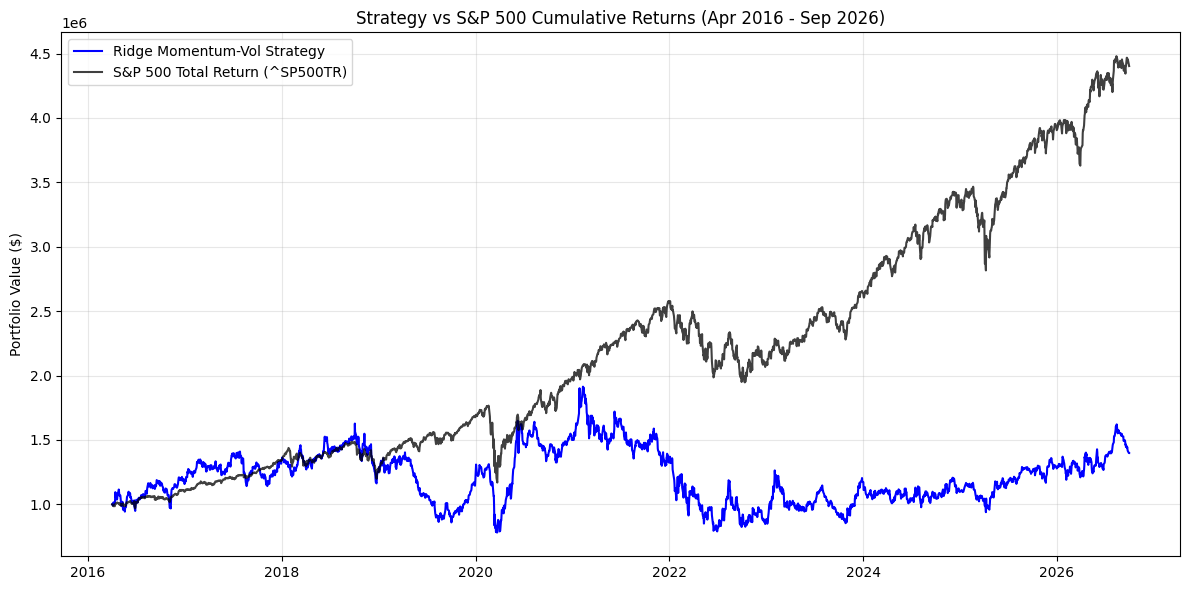

In [6]:
# Fetch ^SP500TR benchmark over the exact test period
bench_df = con.execute(
    "SELECT * FROM benchmark WHERE date >= '2016-04-01' AND date <= '2026-09-30' ORDER BY date"
).df()
bench_df['date'] = pd.to_datetime(bench_df['date'])
bench_df.set_index('date', inplace=True)

val_col = bench_df.select_dtypes(include=[np.number]).columns[0]
bench_df['cumulative_sp500'] = bench_df[val_col] / bench_df[val_col].iloc[0] * INITIAL_CASH

# Align strategy and benchmark
results = bench_df[['cumulative_sp500']].join(portfolio_df[['total_value']], how='inner')
results.rename(columns={'total_value': 'strategy_value'}, inplace=True)

def calc_metrics(series, risk_free_rate=0.02):
    final_value = series.iloc[-1]
    days = (series.index[-1] - series.index[0]).days
    cagr = (final_value / series.iloc[0]) ** (365.25 / days) - 1
    daily_returns = series.pct_change().dropna()
    sharpe = (daily_returns.mean() - risk_free_rate / 252) / daily_returns.std() * np.sqrt(252)
    max_dd = ((series - series.cummax()) / series.cummax()).min()
    return final_value, cagr, sharpe, max_dd

strat_final, strat_cagr, strat_sharpe, strat_mdd = calc_metrics(results['strategy_value'])
bench_final, bench_cagr, bench_sharpe, bench_mdd = calc_metrics(results['cumulative_sp500'])

print(f"{'Metric':<20} | {'Strategy':<15} | {'S&P 500 (^SP500TR)':<18}")
print("-" * 58)
print(f"{'Final Value':<20} | ${strat_final:,.2f} | ${bench_final:,.2f}")
print(f"{'CAGR':<20} | {strat_cagr:.2%}         | {bench_cagr:.2%}")
print(f"{'Sharpe Ratio':<20} | {strat_sharpe:.2f}            | {bench_sharpe:.2f}")
print(f"{'Max Drawdown':<20} | {strat_mdd:.2%}         | {bench_mdd:.2%}")
print(f"\nOutperformance vs Benchmark: ${strat_final - bench_final:+,.2f} ({strat_cagr - bench_cagr:+.2%} CAGR)")

# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(results.index, results['strategy_value'], label='Ridge Momentum-Vol Strategy', color='blue')
plt.plot(results.index, results['cumulative_sp500'], label='S&P 500 Total Return (^SP500TR)', color='black', alpha=0.75)
plt.title('Strategy vs S&P 500 Cumulative Returns (Apr 2016 - Sep 2026)')
plt.ylabel('Portfolio Value ($)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()